soil-type classification

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving soil.zip to soil (1).zip


In [ ]:
import zipfile

zip_path = "soil.zip"  # change this to your filename
extract_path = "/content"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

In [ ]:
import os

base_path = "/content/Soil types"
print(os.listdir(base_path))

['Cinder Soil', 'Yellow Soil', 'Laterite Soil', 'Peat Soil', 'Black Soil']


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_size = 224
batch_size = 32

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    base_path,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical',
    subset='training'
)

val_data = datagen.flow_from_directory(
    base_path,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation'
)

Found 126 images belonging to 5 classes.
Found 30 images belonging to 5 classes.


In [ ]:
import tensorflow as tf

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(5, activation='softmax')  # 5 soil types
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.3333 - loss: 1.8629 - val_accuracy: 0.6000 - val_loss: 1.0719
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.5159 - loss: 1.2403 - val_accuracy: 0.5667 - val_loss: 0.9794
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.6825 - loss: 0.8873 - val_accuracy: 0.7667 - val_loss: 0.8340
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.7381 - loss: 0.6629 - val_accuracy: 0.7333 - val_loss: 0.7658
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.7778 - loss: 0.5986 - val_accuracy: 0.7667 - val_loss: 0.7083
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.8571 - loss: 0.4862 - val_accuracy: 0.8000 - val_loss: 0.6491
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.9127 - loss: 0.3740 - val_accuracy: 0.7667 - val_loss: 0.6342
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.9048 - loss: 0.3368 - val_accuracy: 0.8000 - val_loss: 0.6089
Epoch 9/10
4/4 

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

img_path = "/content/1soil.jpg"  # upload your test image

img = image.load_img(img_path, target_size=(224,224))
img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

class_names = list(train_data.class_indices.keys())
print("Classes:", class_names)

predicted_class = class_names[np.argmax(prediction)]

print("Predicted Soil Type:", predicted_class)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Classes: ['Black Soil', 'Cinder Soil', 'Laterite Soil', 'Peat Soil', 'Yellow Soil']
Predicted Soil Type: Cinder Soil


soil-moisture content

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving soil2_data.csv.xlsx to soil2_data.csv.xlsx


In [ ]:
import pandas as pd

df = pd.read_excel("soil2_data.csv.xlsx")
print(df.head())

    Soil type Moisture_State  Sensor_Value
0  humus_rich            dry           502
1  humus_rich            dry           502
2  humus_rich            dry           502
3  humus_rich            dry           502
4  humus_rich            dry           502


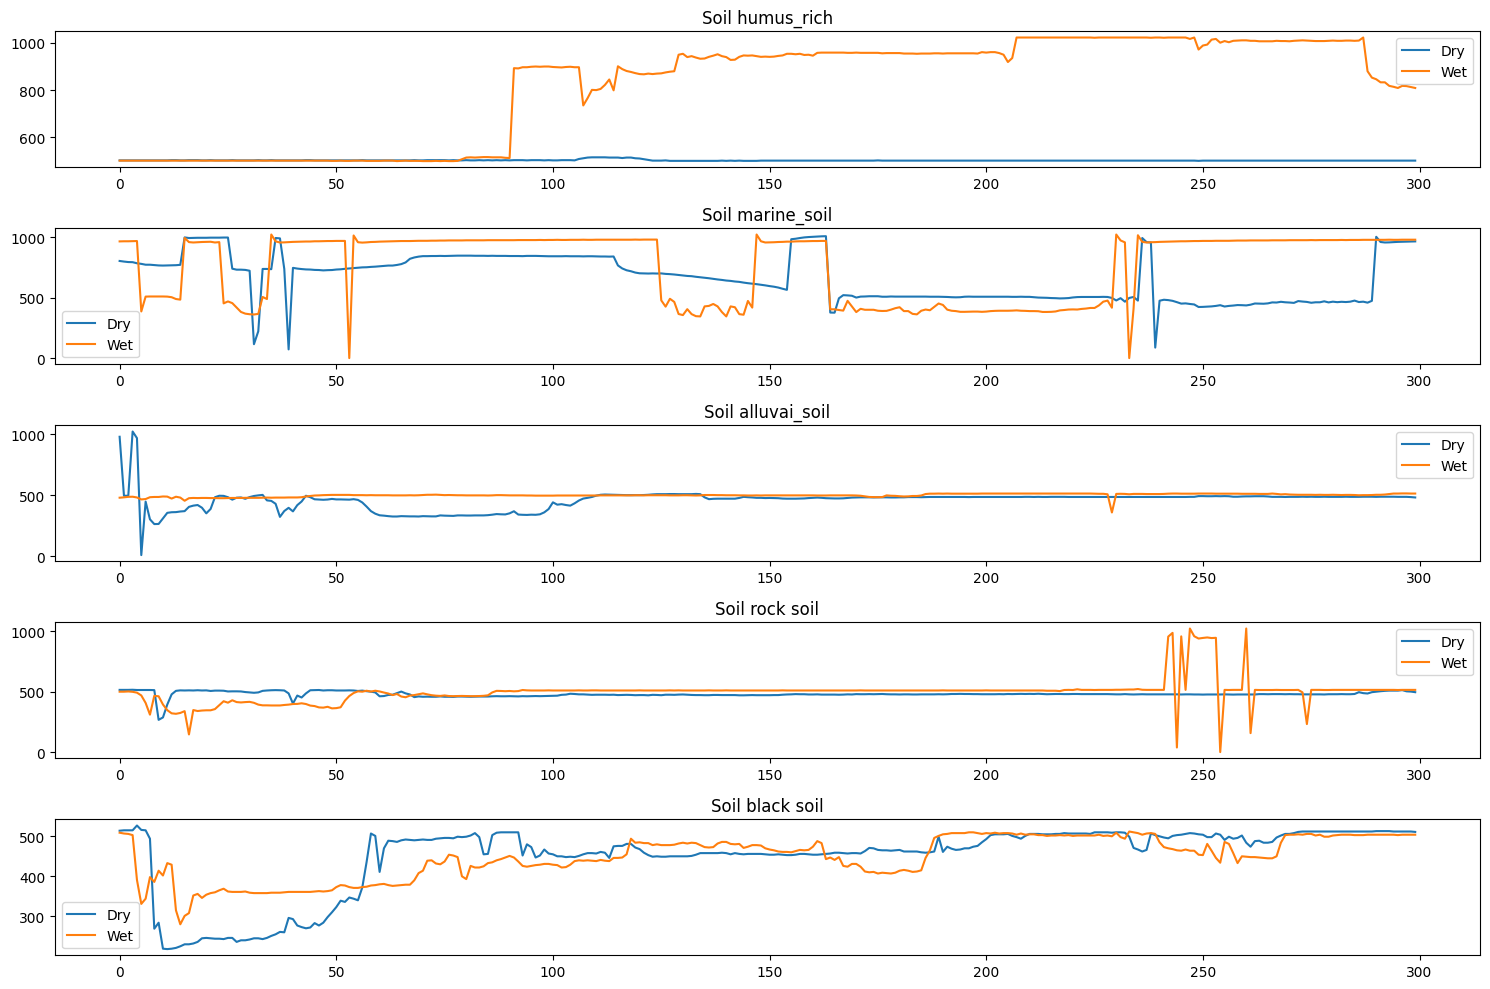

In [ ]:
import matplotlib.pyplot as plt

soils = df["Soil type"].unique()

plt.figure(figsize=(15, 10))

for i, soil in enumerate(soils):

    soil_data = df[df["Soil type"] == soil]

    dry = soil_data[soil_data["Moisture_State"] == "dry"]["Sensor_Value"]
    wet = soil_data[soil_data["Moisture_State"] == "wet"]["Sensor_Value"]

    plt.subplot(len(soils), 1, i+1)
    plt.plot(dry.values, label="Dry")
    plt.plot(wet.values, label="Wet")

    plt.title(f"Soil {soil}")
    plt.legend()

plt.tight_layout()
plt.show()

moisture estimation from the remaining properties

In [ ]:
import pandas as pd

# Load your dataset
df = pd.read_csv("/content/soil_chem/dataset1.csv")

# Clean column names
df.columns = df.columns.str.strip().str.lower()

print(df.head())
print(df.columns)

     n    p    k    ph    ec    oc     s    zn    fe    cu    mn     b  output
0  138  8.6  560  7.46  0.62  0.70   5.9  0.24  0.31  0.77  8.71  0.11       0
1  213  7.5  338  7.62  0.75  1.06  25.4  0.30  0.86  1.54  2.89  2.29       0
2  163  9.6  718  7.59  0.51  1.11  14.3  0.30  0.86  1.57  2.70  2.03       0
3  157  6.8  475  7.64  0.58  0.94  26.0  0.34  0.54  1.53  2.65  1.82       0
4  270  9.9  444  7.63  0.40  0.86  11.8  0.25  0.76  1.69  2.43  2.26       1
Index(['n', 'p', 'k', 'ph', 'ec', 'oc', 's', 'zn', 'fe', 'cu', 'mn', 'b',
       'output'],
      dtype='object')


In [ ]:
X = df[['n','p','k','ec','ph']]
y = df['output']   # 0,1,2

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model_moisture = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

model_moisture.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, n_estimators=200, random_state=42)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model_moisture.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nReport:\n", classification_report(y_test, y_pred))

Accuracy: 0.8920454545454546

Report:
               precision    recall  f1-score   support

           0       0.88      0.97      0.93        78
           1       0.90      0.89      0.89        88
           2       1.00      0.30      0.46        10

    accuracy                           0.89       176
   macro avg       0.93      0.72      0.76       176
weighted avg       0.90      0.89      0.88       176



In [ ]:
def predict_moisture(n, p, k, ec, ph):

    data = [[n, p, k, ec, ph]]
    data = scaler.transform(data)

    pred = model_moisture.predict(data)[0]

    if pred == 0:
        return "Dry"
    elif pred == 1:
        return "Medium"
    else:
        return "Wet"

In [ ]:
result = predict_moisture(40, 30, 20, 2.5, 6.5)
print("Moisture:", result)

Moisture: Dry


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


soil properties

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving soilpro.zip to soilpro (1).zip


In [ ]:
import zipfile

zip_path = "soilpro.zip"   # change name
extract_path = "/content/soil_chem"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted!")

Extracted!


In [ ]:
import os

for root, dirs, files in os.walk("/content/soil_chem"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/content/soil_chem/dataset1.csv


In [ ]:
import os

for root, dirs, files in os.walk("/content/soil_chem"):
    for file in files:
        if file.endswith(".csv"):
            print("Found CSV:", os.path.join(root, file))

Found CSV: /content/soil_chem/dataset1.csv


In [ ]:
import os
print(os.listdir("/content/soil_chem"))

['dataset1.csv']


In [ ]:
import pandas as pd
df = pd.read_csv("/content/soil_chem/dataset1.csv")
print(df.head())

     N    P    K    pH    EC    OC     S    Zn    Fe    Cu    Mn     B  Output
0  138  8.6  560  7.46  0.62  0.70   5.9  0.24  0.31  0.77  8.71  0.11       0
1  213  7.5  338  7.62  0.75  1.06  25.4  0.30  0.86  1.54  2.89  2.29       0
2  163  9.6  718  7.59  0.51  1.11  14.3  0.30  0.86  1.57  2.70  2.03       0
3  157  6.8  475  7.64  0.58  0.94  26.0  0.34  0.54  1.53  2.65  1.82       0
4  270  9.9  444  7.63  0.40  0.86  11.8  0.25  0.76  1.69  2.43  2.26       1


In [ ]:
df.columns = df.columns.str.strip().str.lower()
print(df.columns)

Index(['n', 'p', 'k', 'ph', 'ec', 'oc', 's', 'zn', 'fe', 'cu', 'mn', 'b',
       'output'],
      dtype='object')


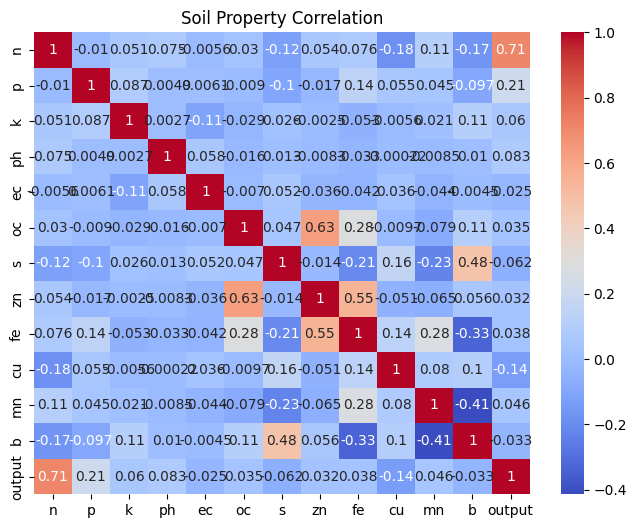

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Soil Property Correlation")
plt.show()

In [ ]:
def classify_soil(row):
    if row['ph'] < 6:
        return "Acidic Soil"
    elif row['ph'] > 7.5:
        return "Alkaline Soil"
    else:
        return "Neutral Soil"

df['soil_class'] = df.apply(classify_soil, axis=1)

print(df['soil_class'].value_counts())

soil_class
Neutral Soil     478
Alkaline Soil    400
Acidic Soil        2
Name: count, dtype: int64


In [ ]:
grouped = df.groupby('soil_class')[['n','p','k','ph','ec']].mean()
print(grouped)

                        n          p           k        ph        ec
soil_class                                                          
Acidic Soil    307.500000   9.250000  375.000000  0.900000  0.540000
Alkaline Soil  251.745000  12.766250  480.062500  7.766075  0.557425
Neutral Soil   242.292887  16.087238  517.167364  7.324289  0.532155


In [ ]:
def get_soil_properties(soil_type):
    if soil_type == "clay":
        return {"ph": 6.5, "N": 50, "P": 30, "K": 25}
    elif soil_type == "sandy":
        return {"ph": 5.5, "N": 20, "P": 15, "K": 10}

In [ ]:
def gpr_adjustment(ph, ec):
    if ec > 2:
        return "High attenuation → increase gain"
    elif ph < 6:
        return "Signal distortion possible"
    else:
        return "Normal filtering"

model(2)mapping the properties to soiltype

In [ ]:
import pandas as pd
import numpy as np

np.random.seed(42)

data = []

soil_config = {
    "black":   {"ph":(7.0,8.5),"n":(60,120),"p":(30,70),"k":(50,100),"ec":(1.5,3.5),"oc":(0.5,1.5)},
    "cinder":  {"ph":(6.5,7.5),"n":(10,40),"p":(5,20),"k":(5,20),"ec":(0.5,1.5),"oc":(0.1,0.5)},
    "laterite":{"ph":(5.0,6.5),"n":(10,40),"p":(5,25),"k":(20,50),"ec":(0.5,2.0),"oc":(0.2,0.8)},
    "peat":    {"ph":(3.5,5.5),"n":(30,80),"p":(5,20),"k":(5,30),"ec":(1.0,2.5),"oc":(2.0,5.0)},
    "yellow":  {"ph":(5.5,6.8),"n":(30,70),"p":(20,60),"k":(10,40),"ec":(0.5,2.0),"oc":(0.5,1.2)}
}

for soil, ranges in soil_config.items():
    for _ in range(300):  # 300 samples each

        ph = np.random.uniform(*ranges["ph"])
        n  = np.random.uniform(*ranges["n"])
        p  = np.random.uniform(*ranges["p"])
        k  = np.random.uniform(*ranges["k"])
        ec = np.random.uniform(*ranges["ec"])
        oc = np.random.uniform(*ranges["oc"])

        moisture = np.random.choice([0,1,2])  # 0=dry,1=medium,2=wet

        data.append([soil, ph, n, p, k, ec, oc, moisture])

df = pd.DataFrame(data, columns=[
    "soil_type","ph","n","p","k","ec","organic_carbon","moisture"
])

print(df.head())

  soil_type        ph           n          p          k        ec  \
0     black  7.561810  117.042858  59.279758  79.932924  1.812037   
1     black  7.688873   80.022517  35.714673  82.544424  1.612823   
2     black  7.318509   70.909498  37.336180  65.212112  2.549513   
3     black  7.787162   83.991658  31.866627  98.687776  1.965543   
4     black  7.299511   90.854066  53.696583  52.322521  2.715090   

   organic_carbon  moisture  
0        0.655995         2  
1        1.221999         1  
2        0.931945         0  
3        0.590606         1  
4        0.670524         2  


In [ ]:
df.to_csv("soil_dataset_5types.csv", index=False)

In [ ]:
import pandas as pd

df = pd.read_csv("soil_dataset_5types.csv")
df.columns = df.columns.str.strip().str.lower()

soil_properties = df.groupby('soil_type')[[
    'ph','n','p','k','ec','organic_carbon'
]].mean()

In [ ]:
soil_type = input("Enter soil type (black/cinder/laterite/peat/yellow): ").lower()
moisture = int(input("Enter moisture (0=dry,1=medium,2=wet): "))

Enter soil type (black/cinder/laterite/peat/yellow): cinder
Enter moisture (0=dry,1=medium,2=wet): 0


In [ ]:
props = soil_properties.loc[soil_type]

ph = props['ph']
ec = props['ec']

print("\nSoil Properties:")
print("pH:", ph)
print("EC:", ec)


Soil Properties:
pH: 7.018127876382755
EC: 0.992680789459323


In [ ]:
def get_filter_params(moisture, ec):

    if moisture == 2:
        k = 9
    elif moisture == 1:
        k = 7
    else:
        k = 5

    if ec > 2.5:
        k += 2

    if k % 2 == 0:
        k += 1

    return k

In [ ]:
import cv2
import numpy as np

def adaptive_gpr(gpr_signal, moisture, ec):

    # Normalize
    gpr = (gpr_signal - np.min(gpr_signal)) / (np.max(gpr_signal) - np.min(gpr_signal))

    # Adaptive filter
    k = get_filter_params(moisture, ec)
    filtered = cv2.GaussianBlur(gpr, (k,k), 0)

    # Background removal
    background = np.mean(filtered, axis=0)
    cleaned = filtered - background

    # Thresholding
    thresh = np.mean(cleaned) + 0.5*np.std(cleaned)
    final = np.where(cleaned > thresh, cleaned, 0)

    return final

In [ ]:
gpr_final = adaptive_gpr(gpr_noisy, moisture, ec)

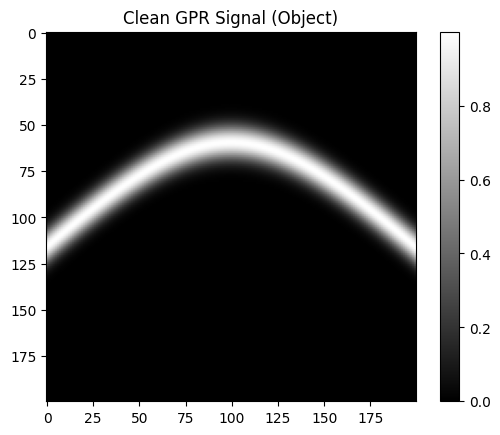

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Grid
x = np.linspace(0, 100, 200)
t = np.linspace(0, 100, 200)
X, T = np.meshgrid(x, t)

# Hyperbola (object)
x0 = 50   # object position
depth = 30

gpr = np.exp(-((T - np.sqrt((X - x0)**2 + depth**2))**2)/20)

plt.imshow(gpr, cmap='gray')
plt.title("Clean GPR Signal (Object)")
plt.colorbar()
plt.show()

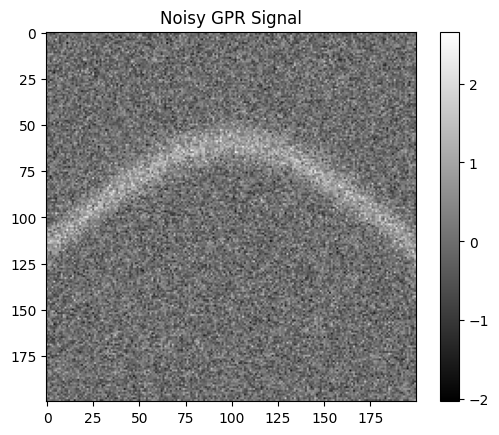

In [ ]:
noise = np.random.normal(0, 0.5, gpr.shape)
gpr_noisy = gpr + noise

plt.imshow(gpr_noisy, cmap='gray')
plt.title("Noisy GPR Signal")
plt.colorbar()
plt.show()

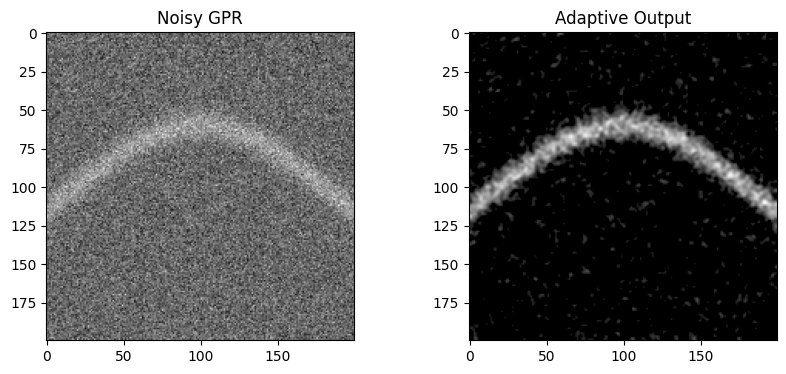

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(gpr_noisy, cmap='gray')
plt.title("Noisy GPR")

plt.subplot(1,2,2)
plt.imshow(gpr_final, cmap='gray')
plt.title("Adaptive Output")

plt.show()

new

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Grid
x = np.linspace(0, 100, 200)
t = np.linspace(0, 100, 200)
X, T = np.meshgrid(x, t)

In [ ]:
def generate_gpr(x0, depth, strength, spread):

    hyperbola = np.exp(-((T - np.sqrt((X - x0)**2 + depth**2))**2)/spread)

    return strength * hyperbola

In [ ]:
gpr_metal = generate_gpr(
    x0=50,
    depth=30,
    strength=1.5,   # strong reflection
    spread=10       # sharp
)

In [ ]:
gpr_plastic = generate_gpr(
    x0=50,
    depth=30,
    strength=0.6,   # weak reflection
    spread=25       # blurred
)

In [ ]:
noise = np.random.normal(0, 0.4, gpr_metal.shape)

gpr_metal_noisy = gpr_metal + noise
gpr_plastic_noisy = gpr_plastic + noise

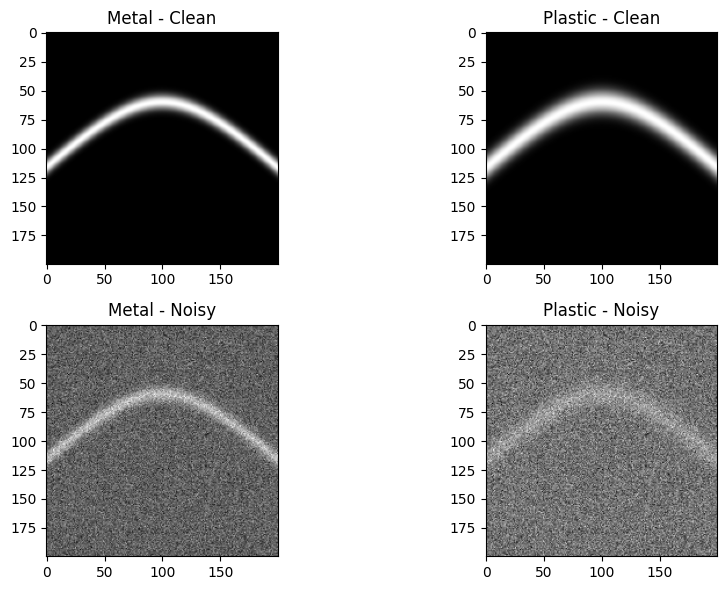

In [ ]:
plt.figure(figsize=(10,6))

plt.subplot(2,2,1)
plt.imshow(gpr_metal, cmap='gray')
plt.title("Metal - Clean")

plt.subplot(2,2,2)
plt.imshow(gpr_plastic, cmap='gray')
plt.title("Plastic - Clean")

plt.subplot(2,2,3)
plt.imshow(gpr_metal_noisy, cmap='gray')
plt.title("Metal - Noisy")

plt.subplot(2,2,4)
plt.imshow(gpr_plastic_noisy, cmap='gray')
plt.title("Plastic - Noisy")

plt.tight_layout()
plt.show()

# New section